In [46]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

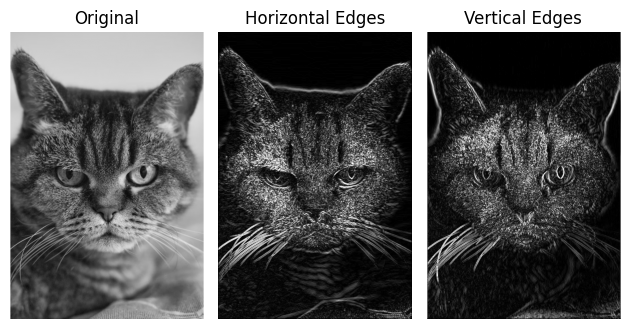

In [47]:
image = cv2.imread("cat.png", 0)
h, w = image.shape

sobel_x = [[-1, 0, 1],
           [-2, 0, 2],
           [-1, 0, 1]]

sobel_y = [[-1, -2, -1],
           [ 0,  0,  0],
           [ 1,  2,  1]]

vertical = np.zeros((h, w), dtype=np.uint8)
horizontal = np.zeros((h, w), dtype=np.uint8)

for i in range(1, h - 1):
    for j in range(1, w - 1):
        gx = 0
        gy = 0

        for a in range(3):
            for b in range(3):
                pixel = int(image[i + a - 1, j + b - 1])
                gx += pixel * sobel_x[a][b]
                gy += pixel * sobel_y[a][b]

        vertical[i, j] = min(255, abs(gx))
        horizontal[i, j] = min(255, abs(gy))

images = [image, horizontal, vertical]
titles = ["Original", "Horizontal Edges", "Vertical Edges"]

for k in range(3):
    plt.subplot(1, 3, k + 1)
    plt.imshow(images[k], cmap="gray", vmin=0, vmax=255)
    plt.title(titles[k])
    plt.axis("off")

plt.tight_layout()
plt.show()